# BÀI TẬP 4.3: PHÂN CỤM VĂN BẢN (20 NEWSGROUPS) BẰNG K-MEANS & LSA

**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)

In [1]:
# 1. Thu thập dữ liệu văn bản và chuyển đổi đặc trưng bằng TF-IDF
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer

# Lựa chọn 3 nhóm chủ đề tin tức cần phân loại
target_topics = ['talk.politics.guns', 'sci.space', 'soc.religion.christian']
news_data = fetch_20newsgroups(subset='all', categories=target_topics, shuffle=True, random_state=10)

# Khởi tạo mô hình TF-IDF với ngưỡng lọc tần suất tùy chỉnh
tfidf_transformer = TfidfVectorizer(max_df=0.6, min_df=4, stop_words='english')
X_features = tfidf_transformer.fit_transform(news_data.data)

print(f"Tổng số lượng tài liệu: {X_features.shape[0]}")
print(f"Số lượng chiều đặc trưng từ vựng: {X_features.shape[1]}")

Tổng số lượng tài liệu: 2894
Số lượng chiều đặc trưng từ vựng: 12748


In [2]:
# 2. Giảm số chiều dữ liệu bằng kỹ thuật phân tích ngữ nghĩa tiềm ẩn (LSA - TruncatedSVD)
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

# Nén không gian từ vựng xuống 100 chiều và chuẩn hóa vector để đo khoảng cách Cosine chuẩn xác
svd_reducer = TruncatedSVD(n_components=100, random_state=42)
X_embedded = normalize(svd_reducer.fit_transform(X_features))

ratio = svd_reducer.explained_variance_ratio_.sum() * 100
print(f"Tỷ lệ phương sai giữ lại sau khi nén LSA 100 chiều: {ratio:.2f}%")

Tỷ lệ phương sai giữ lại sau khi nén LSA 100 chiều: 25.29%


In [3]:
# 3. Huấn luyện mô hình K-Means và đo lường độ chính xác phân cụm
from sklearn.cluster import KMeans
from sklearn import metrics

# Phân chia dữ liệu thành 3 nhóm tương ứng với 3 chủ đề tin
clustering_model = KMeans(n_clusters=3, max_iter=100, n_init=5, random_state=42)
pred_labels = clustering_model.fit_predict(X_embedded)

# Đánh giá bằng các độ đo phân cụm chuẩn mực
v_measure = metrics.v_measure_score(news_data.target, pred_labels)
ari = metrics.adjusted_rand_score(news_data.target, pred_labels)
sil = metrics.silhouette_score(X_embedded, pred_labels, sample_size=2000, random_state=42)

print("=" * 55)
print("       ĐÁNH GIÁ CHẤT LƯỢNG PHÂN CỤM K-MEANS")
print("=" * 55)
print(f"1. V-measure Score          : {v_measure:.4f}")
print(f"2. Adjusted Rand Index (ARI) : {ari:.4f}")
print(f"3. Silhouette Coefficient    : {sil:.4f}")
print("=" * 55)

       ĐÁNH GIÁ CHẤT LƯỢNG PHÂN CỤM K-MEANS
1. V-measure Score          : 0.8663
2. Adjusted Rand Index (ARI) : 0.9112
3. Silhouette Coefficient    : 0.0468


In [4]:
# 4. Trích xuất các từ khóa đặc trưng đại diện cho từng cụm chủ đề
import numpy as np

# Chiếu tâm cụm ngược trở lại không gian từ vựng ban đầu
dictionary = np.array(tfidf_transformer.get_feature_names_out())
center_points = svd_reducer.inverse_transform(clustering_model.cluster_centers_)

print("=== CÁC TỪ KHÓA NỔI BẬT THEO TỪNG CỤM ===")
for cluster_idx in range(3):
    top_indices = np.argsort(center_points[cluster_idx])[-10:][::-1]
    keywords = dictionary[top_indices]
    print(f"Chủ đề {cluster_idx + 1}: {' | '.join(keywords)}")

=== CÁC TỪ KHÓA NỔI BẬT THEO TỪNG CỤM ===
Chủ đề 1: com | gun | fbi | people | guns | stratus | government | batf | atf | article
Chủ đề 2: space | nasa | access | com | henry | moon | digex | shuttle | toronto | pat
Chủ đề 3: god | jesus | christian | church | christ | bible | people | christians | faith | christianity


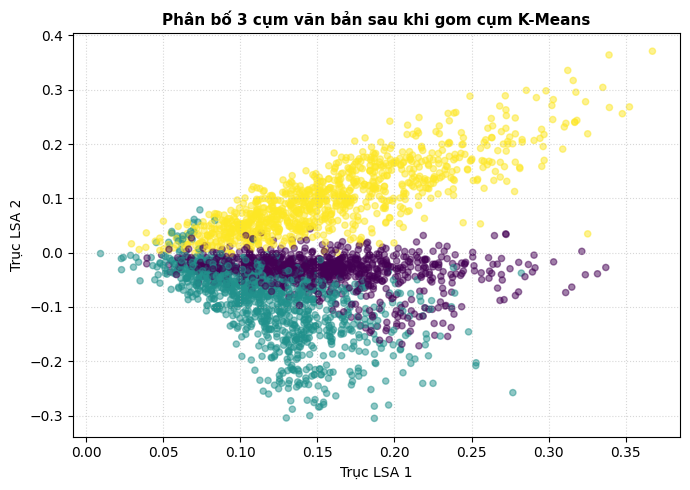

In [5]:
# 5. Trực quan hóa kết quả phân cụm trên không gian 2 chiều (LSA 2D)
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

# Giảm dữ liệu xuống 2 chiều phẳng để vẽ đồ thị phân tán
coords_2d = TruncatedSVD(n_components=2, random_state=42).fit_transform(X_features)

plt.figure(figsize=(7, 5))
plt.scatter(coords_2d[:, 0], coords_2d[:, 1], c=pred_labels, cmap='viridis', alpha=0.5, s=20)
plt.title("Phân bố 3 cụm văn bản sau khi gom cụm K-Means", fontsize=11, fontweight='bold')
plt.xlabel("Trục LSA 1")
plt.ylabel("Trục LSA 2")
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()